# tumbleweed - error analysis plots

Reads the CSVs produced by `eval.py`/`train.py` and plots them. This notebook is deliberately a thin layer: the actual metric definitions (`flip_rate`, `distribution_stats`, etc.) live in `tumbleweed/metrics.py`, not here - if you find yourself writing real analysis logic in a cell below, it probably belongs in that module instead so `scripts/analyze_errors.py` and future code can reuse it too.

Two data sources:
- **Per-sample CSV** (`results/*.csv`, from `eval.py --advanced`): one row per validation image with true/predicted pose and per-sample errors.
- **Per-epoch CSV** (`checkpoints/metrics.csv`, from `train.py`): one row per training epoch with distribution stats over the validation set.

Edit the paths in the config cell below to point at whichever run you want to look at.

## commands to copy / paste

```bash
# 1. Train - writes checkpoints/{best,last}.pt and checkpoints/metrics.csv (one row per epoch)
caffeinate -i uv run python -m tumbleweed.train --data-root data/speedplusv2 --epochs 30 --device mps

# 2. Evaluate a checkpoint with the full per-sample breakdown
#    (writes results/<checkpoint-stem>_<domain>-<split>.csv by default)
uv run python -m tumbleweed.eval --data-root data/speedplusv2 --checkpoint checkpoints/best.pt --device mps --advanced

# 3. (optional) console-only version of this notebook's per-sample analysis
uv run python scripts/analyze_errors.py --csv results/best_synthetic-validation.csv

Useful `eval.py` flags: `--domain` (`synthetic`/`lightbox`/`sunlamp`), `--split` (`train`/`validation`/`test`), `--error-csv <path>` to override the auto-derived output path. Whatever CSV you produce, point `PER_SAMPLE_CSV` (and `METRICS_CSV`) at it in the config cell below.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["figure.figsize"] = (8, 4.5)
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

In [2]:
# --- config: point these at the run you want to look at ---
PER_SAMPLE_CSV = REPO_ROOT / "results" / "best_synthetic-validation_0901.csv"
METRICS_CSV = REPO_ROOT / "checkpoints" / "metrics.csv"
FLIP_THRESHOLD_DEG = 90.0

# data-root/domain the above CSV was evaluated against - needed to locate the
# actual images for the GT-vs-predicted overlay section below.
DATA_ROOT = REPO_ROOT / "data" / "speedplusv2"
DOMAIN = "synthetic"

## Per-sample error distribution

In [3]:
df = pd.read_csv(PER_SAMPLE_CSV)
df["is_flip"] = df["rotation_error_deg"] > FLIP_THRESHOLD_DEG
print(f"n = {len(df)}, flip_rate = {df['is_flip'].mean():.4f}")
df[["translation_error", "rotation_error_deg"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99])

n = 11994, flip_rate = 0.0216


,translation_error,rotation_error_deg
count,11994.000000,11994.000000
mean,0.040802,16.917830
std,0.037048,21.489327
min,0.001007,0.318981
50%,0.032844,11.201789
90%,0.077613,29.033307
95%,0.097063,47.022715
99%,0.153224,137.008213
max,1.875758,179.855957


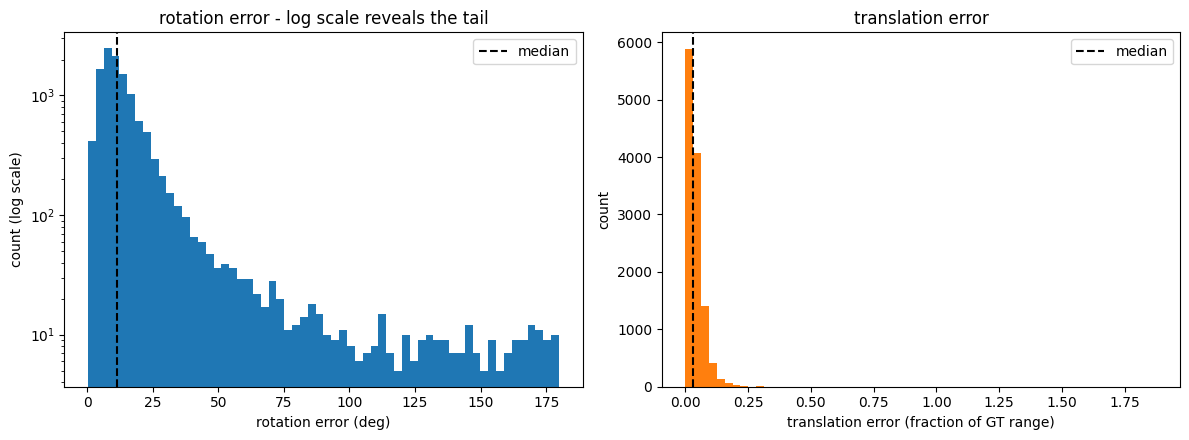

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(df["rotation_error_deg"], bins=60, color="tab:blue")
axes[0].axvline(df["rotation_error_deg"].median(), color="black", linestyle="--", label="median")
axes[0].set_yscale("log")
axes[0].set_xlabel("rotation error (deg)")
axes[0].set_ylabel("count (log scale)")
axes[0].set_title("rotation error - log scale reveals the tail")
axes[0].legend()

axes[1].hist(df["translation_error"], bins=60, color="tab:orange")
axes[1].axvline(df["translation_error"].median(), color="black", linestyle="--", label="median")
axes[1].set_xlabel("translation error (fraction of GT range)")
axes[1].set_ylabel("count")
axes[1].set_title("translation error")
axes[1].legend()

fig.tight_layout()

## where do errors concentrate?

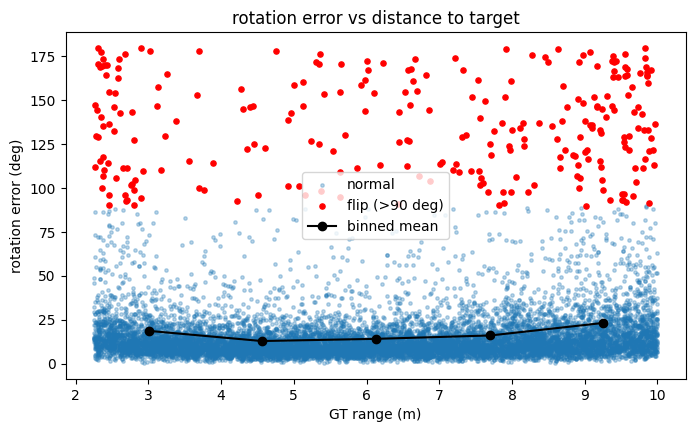

In [5]:
fig, ax = plt.subplots()

normal = df[~df["is_flip"]]
flips = df[df["is_flip"]]
ax.scatter(normal["gt_range_m"], normal["rotation_error_deg"], s=6, alpha=0.3, label="normal")
ax.scatter(flips["gt_range_m"], flips["rotation_error_deg"], s=14, color="red", label=f"flip (>{FLIP_THRESHOLD_DEG:.0f} deg)")

# binned mean, same bins as scripts/analyze_errors.py
num_bins = 5
df["range_bin"] = pd.qcut(df["gt_range_m"], num_bins)
binned = df.groupby("range_bin", observed=True)["rotation_error_deg"].mean()
bin_centers = [interval.mid for interval in binned.index]
ax.plot(bin_centers, binned.values, color="black", marker="o", label="binned mean")

ax.set_xlabel("GT range (m)")
ax.set_ylabel("rotation error (deg)")
ax.set_title("rotation error vs distance to target")
ax.legend()

## Worst cases

In [6]:
df.sort_values("rotation_error_deg", ascending=False).head(15)[
    ["filename", "rotation_error_deg", "translation_error", "gt_range_m",
     "q_gt_w", "q_gt_x", "q_gt_y", "q_gt_z", "q_pred_w", "q_pred_x", "q_pred_y", "q_pred_z"]
]

,filename,rotation_error_deg,translation_error,gt_range_m,q_gt_w,q_gt_x,q_gt_y,q_gt_z,q_pred_w,q_pred_x,q_pred_y,q_pred_z
7569,img038083.jpg,179.855957,0.048678,9.831924,0.706286,0.278384,-0.617454,-0.205943,-0.261885,-0.304179,-0.649920,0.645365
7553,img037980.jpg,179.733704,0.026138,2.902975,0.257404,-0.601646,-0.594390,0.467403,0.526922,0.599377,-0.559114,-0.224703
3299,img016574.jpg,179.594910,0.292271,2.314369,-0.236208,-0.696721,-0.316848,0.598659,0.420640,0.434009,-0.744806,0.282776
10728,img053684.jpg,179.169968,0.038823,8.636505,0.405454,-0.618793,0.486408,-0.464877,-0.562905,0.090445,-0.193673,-0.798404
6655,img033273.jpg,179.101273,0.014284,7.912466,-0.194088,0.050113,-0.979614,-0.013199,0.840890,-0.394576,-0.190514,-0.317678
11824,img059065.jpg,178.302216,0.044567,3.700234,-0.421505,0.752184,0.379108,-0.335901,0.112035,0.416190,-0.871006,-0.235761
8373,img042061.jpg,178.263382,0.101691,3.025728,-0.596586,0.339917,0.399578,-0.607355,-0.519036,-0.209329,-0.819742,-0.121678
9265,img046398.jpg,178.227310,0.037293,4.755057,0.311868,-0.747713,-0.585437,-0.030454,-0.102922,0.542420,-0.788172,0.271979
3819,img019099.jpg,177.715820,0.510760,2.352917,0.248508,0.534957,-0.286084,0.755130,0.706648,0.378360,0.532152,-0.272591
7850,img039510.jpg,177.442902,0.037500,9.075628,-0.279104,0.079257,-0.937568,0.191795,0.082278,0.168382,0.164061,0.968484


## Visual comparison: GT vs predicted pose overlay

The table above tells you *which* images are worst; this projects both the ground-truth and predicted pose onto the actual image so you can see *what the failure looks like* - e.g. whether a large rotation error is a plausible symmetry flip (predicted triad roughly matches a rotated/mirrored version of the object) or an unrelated garbage prediction.

Solid axes = ground truth, dashed axes = predicted. Axis colors: X=red, Y=green, Z=blue. Reuses `project_points`/`draw_pose` from `tumbleweed.geometry.projection` - the same code `scripts/sanity_check_projection.py` uses to validate label parsing - so this is guaranteed consistent with that sanity check rather than a second implementation of the projection math.

In [7]:
import cv2

from tumbleweed.data.camera import load_camera
from tumbleweed.geometry.projection import axis_points, draw_pose, project_points

camera = load_camera(DATA_ROOT / "camera.json")
image_dir = DATA_ROOT / DOMAIN / "images"


def overlay_gt_and_pred(row: pd.Series, axis_length: float = 0.5) -> np.ndarray:
    """Project GT (solid) + predicted (dashed) axis triads onto one CSV row's image, as RGB."""
    image_path = image_dir / row["filename"]
    image = cv2.imread(str(image_path))
    if image is None:
        raise FileNotFoundError(f"Could not read image: {image_path}")

    points_body, colors = axis_points(length=axis_length)

    q_gt = row[["q_gt_w", "q_gt_x", "q_gt_y", "q_gt_z"]].to_numpy(dtype=np.float64)
    t_gt = row[["t_gt_x", "t_gt_y", "t_gt_z"]].to_numpy(dtype=np.float64)
    q_pred = row[["q_pred_w", "q_pred_x", "q_pred_y", "q_pred_z"]].to_numpy(dtype=np.float64)
    t_pred = row[["t_pred_x", "t_pred_y", "t_pred_z"]].to_numpy(dtype=np.float64)

    gt_2d = project_points(points_body, q_gt, t_gt, camera)
    pred_2d = project_points(points_body, q_pred, t_pred, camera)

    out = draw_pose(image, gt_2d, colors)
    out = draw_pose(out, pred_2d, colors, dashed=True, origin_color=None)
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)

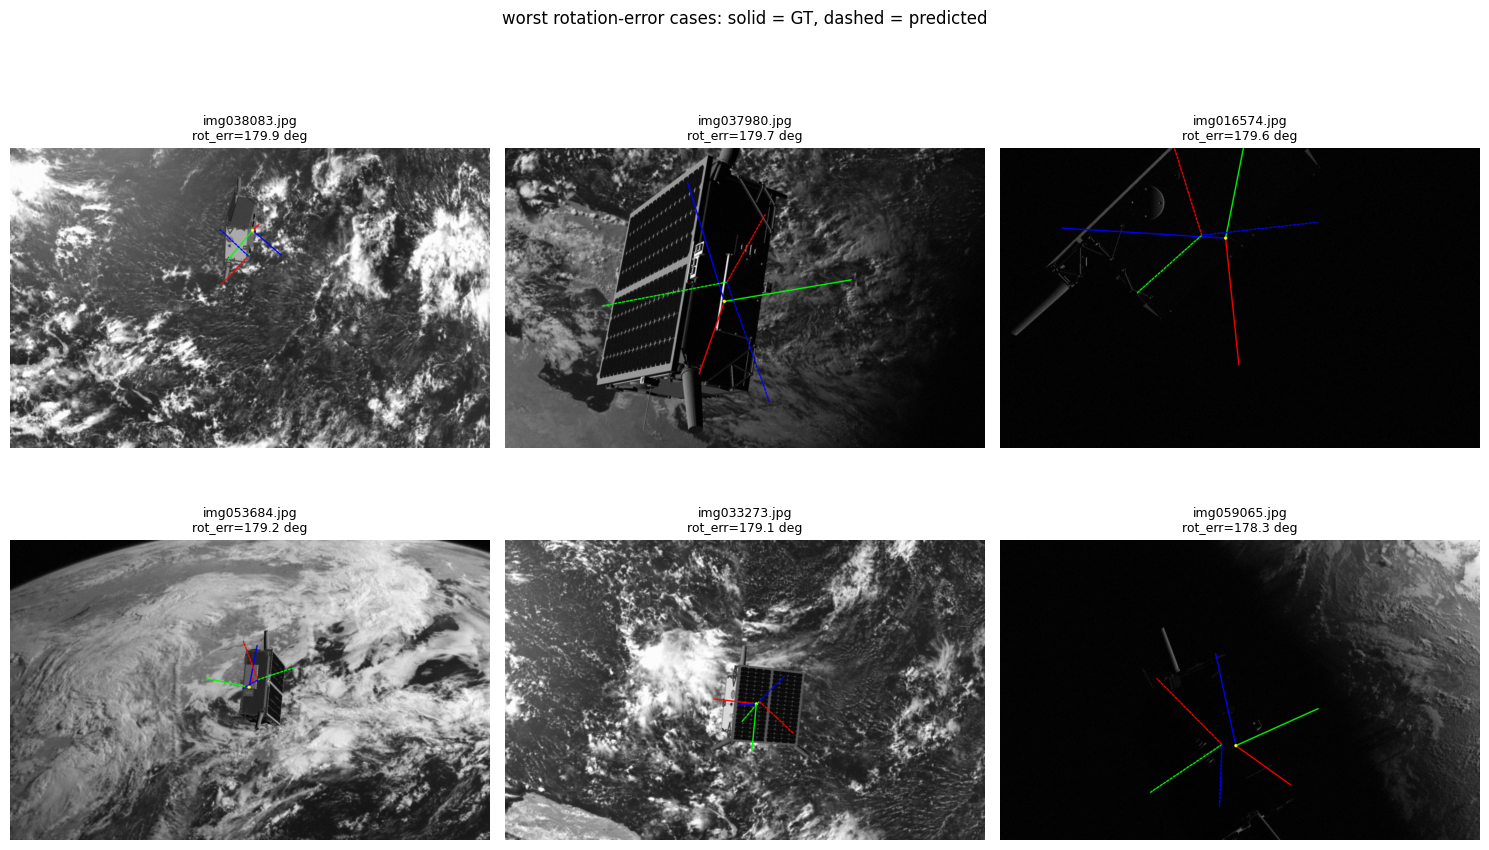

In [8]:
N_WORST = 6
worst_rows = df.sort_values("rotation_error_deg", ascending=False).head(N_WORST)

ncols = 3
nrows = int(np.ceil(N_WORST / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
axes = np.atleast_1d(axes).flatten()

for ax, (_, row) in zip(axes, worst_rows.iterrows()):
    ax.imshow(overlay_gt_and_pred(row))
    ax.set_title(f"{row['filename']}\nrot_err={row['rotation_error_deg']:.1f} deg", fontsize=9)
    ax.axis("off")

for ax in axes[len(worst_rows):]:
    ax.axis("off")

fig.suptitle("worst rotation-error cases: solid = GT, dashed = predicted", y=1.02)
fig.tight_layout()

## Per-epoch training curves

Needs `checkpoints/metrics.csv`, written by `train.py` (one row per epoch). If you haven't retrained since that logging was added, this file won't exist yet - it'll show up after the next training run.

In [9]:
if not METRICS_CSV.exists():
    print(f"{METRICS_CSV} doesn't exist yet - run training to generate it.")
    epochs_df = None
else:
    epochs_df = pd.read_csv(METRICS_CSV)
    display(epochs_df)

,epoch,train_loss,num_samples,mean_translation_error,median_translation_error,std_translation_error,p90_translation_error,p95_translation_error,mean_rotation_error_deg,median_rotation_error_deg,std_rotation_error_deg,p90_rotation_error_deg,p95_rotation_error_deg,flip_rate_90deg,mean_speed_score
0,1,1.495299,11994,0.098357,0.081298,0.076946,0.187193,0.234729,45.433903,31.952093,38.449348,102.877739,140.129242,0.125229,0.891328
1,2,0.812295,11994,0.060991,0.050686,0.052297,0.111860,0.140072,32.289310,21.514734,31.464262,68.788750,105.832848,0.067200,0.624546
2,3,0.724515,11994,0.053800,0.042168,0.053613,0.101760,0.131233,29.181158,20.365580,28.170748,58.515968,90.377258,0.050359,0.563107
3,4,0.671511,11994,0.054211,0.042690,0.055863,0.102009,0.127408,27.196468,19.138323,26.571253,52.834427,81.735832,0.041604,0.528879
4,5,0.615792,11994,0.053792,0.043339,0.046353,0.101618,0.127717,31.115204,21.932037,29.205212,62.994904,94.782387,0.054694,0.596855
5,6,0.634234,11994,0.059870,0.046112,0.056261,0.117014,0.150650,30.873974,21.469826,29.544338,62.127460,96.581268,0.056278,0.598722
6,7,0.605381,11994,0.050710,0.041862,0.040793,0.097273,0.119463,25.661253,18.494398,25.004299,48.256794,72.887360,0.035351,0.498583
7,8,0.573207,11994,0.045517,0.035976,0.047148,0.086627,0.109974,23.743841,15.966460,25.719204,45.465828,73.200699,0.036685,0.459925
8,9,0.567747,11994,0.055451,0.046122,0.042069,0.106327,0.129141,26.983572,18.758732,27.388552,52.356365,81.312370,0.042855,0.526404
9,10,0.549644,11994,0.049823,0.041045,0.044333,0.095252,0.115874,22.748760,15.809451,24.612617,41.867702,66.446114,0.031849,0.446864


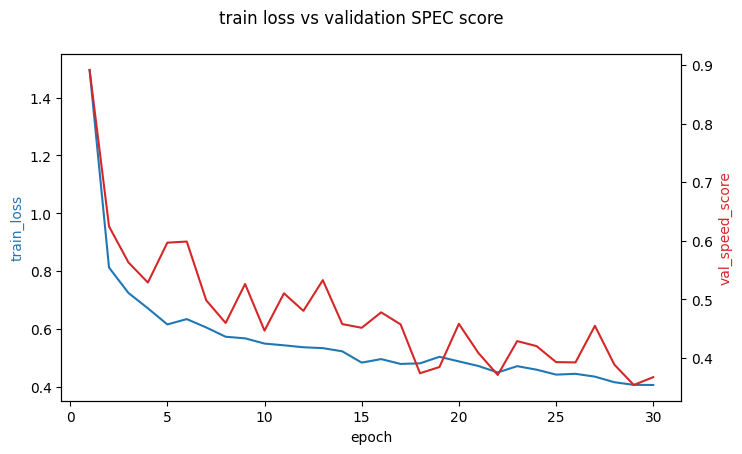

In [10]:
if epochs_df is not None:
    fig, ax1 = plt.subplots()
    ax1.plot(epochs_df["epoch"], epochs_df["train_loss"], color="tab:blue", label="train_loss")
    ax1.set_xlabel("epoch")
    ax1.set_ylabel("train_loss", color="tab:blue")

    ax2 = ax1.twinx()
    ax2.plot(epochs_df["epoch"], epochs_df["mean_speed_score"], color="tab:red", label="val_speed_score")
    ax2.set_ylabel("val_speed_score", color="tab:red")

    fig.suptitle("train loss vs validation SPEC score")

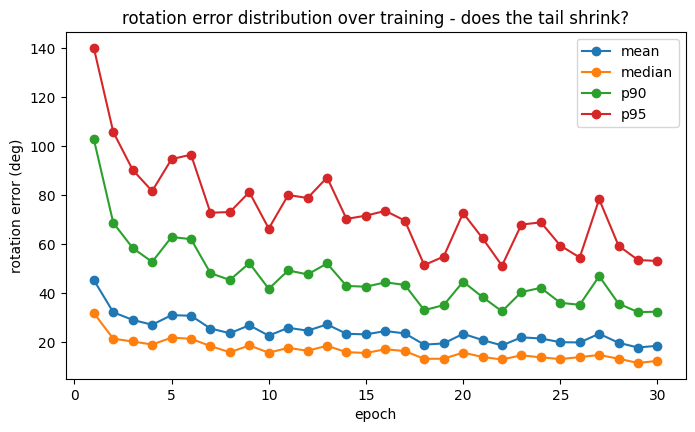

In [11]:
if epochs_df is not None:
    fig, ax = plt.subplots()
    for col, label in [
        ("mean_rotation_error_deg", "mean"),
        ("median_rotation_error_deg", "median"),
        ("p90_rotation_error_deg", "p90"),
        ("p95_rotation_error_deg", "p95"),
    ]:
        ax.plot(epochs_df["epoch"], epochs_df[col], marker="o", label=label)
    ax.set_xlabel("epoch")
    ax.set_ylabel("rotation error (deg)")
    ax.set_title("rotation error distribution over training - does the tail shrink?")
    ax.legend()

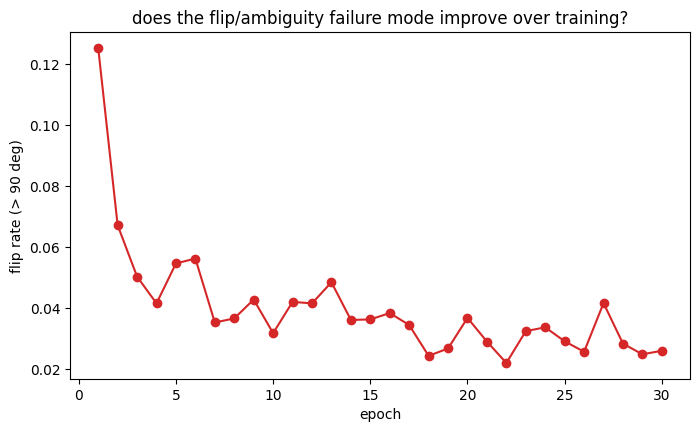

In [12]:
if epochs_df is not None:
    fig, ax = plt.subplots()
    ax.plot(epochs_df["epoch"], epochs_df["flip_rate_90deg"], marker="o", color="tab:red")
    ax.set_xlabel("epoch")
    ax.set_ylabel("flip rate (> 90 deg)")
    ax.set_title("does the flip/ambiguity failure mode improve over training?")